# BRACOL Coffee Leaf Disease Classifier (PyTorch baseline)

Predicts the most likely condition of a coffee leaf photo: healthy, or one of the BRACOL stress classes (e.g., rust, leaf miner, leaf spots).

**What this notebook does**
1. Inspects the dataset folders
2. Fine-tunes a pretrained MobileNetV3-Large (classifier head first, then the whole network)
3. Evaluates on the test split with per-class recall and a confusion matrix
4. Uses Grad-CAM to check what the model actually looks at
5. Measures how performance degrades as test images get lower resolution

**Setup**
- Download BRACOL from Mendeley Data (https://data.mendeley.com/datasets/yy2k5y8mxg) and unzip it.
- The notebook assumes the **whole-leaf** images are arranged as `DATA_DIR/{train,val,test}/<class_name>/*.jpg`. I have not confirmed that the BRACOL download uses exactly this layout. Run the inspect cell first. If the layout is different (for example, labels in a CSV file), the data-loading cells need adjusting.
- Requires: `torch`, `torchvision`, `scikit-learn`, `matplotlib`, `pillow`. A GPU helps a lot (the free Colab tier works).

In [1]:
# Uncomment if you need to install dependencies (e.g., on a fresh Colab runtime)
# !pip install torch torchvision scikit-learn matplotlib pillow

In [ ]:
import os, re, random, time, copy, json
from tqdm.auto import tqdm
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader
from torchvision import datasets, transforms, models

from sklearn.metrics import classification_report, confusion_matrix, f1_score, recall_score
from sklearn.model_selection import train_test_split


def set_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)


set_seed(42)
device = torch.device("cpu")
print("Device:", device)

Device: cpu


In [3]:
import sys
_orig = sys.unraisablehook
def _quiet(u):
    if "can only test a child process" in str(u.exc_value):
        return
    _orig(u)
sys.unraisablehook = _quiet

## 1. Configuration

In [4]:
IMAGE_DIR = Path("data/leaf/images")
LABELS_CSV = Path("data/leaf/dataset.csv")
# IMAGE_DIR = Path("leaf_images")               # folder with the leaf images (searched recursively)
# LABELS_CSV = Path("dataset.csv")   # path to the labels CSV (adjust to your file's name)
EXCLUDE_KEYWORDS = ("mask", "symptom")        # ignore image paths containing these words
USE_PROVIDED_SPLITS = True                    # use train/val/test folders if the images are organized that way
IMG_SIZE = 224                         # model input size
BATCH_SIZE = 32
EPOCHS_HEAD = 3                        # phase 1: train only the new classifier head
EPOCHS_FINETUNE = 15                   # phase 2: fine-tune the whole network
LR_HEAD = 1e-3
LR_FINETUNE = 1e-4
WEIGHT_DECAY = 1e-4
NUM_WORKERS = 0

OUT_DIR = Path("outputs")
OUT_DIR.mkdir(exist_ok=True)

## 2. Load the labels and match them to images

BRACOL stores labels in a CSV rather than in class folders. Columns: `id`, `predominant_stress` (the label we train on), one 0/1 flag per stress (`miner`, `rust`, `phoma`, `cercospora`), and `severity`.

The class names (0 = healthy, 1 = miner, 2 = rust, 3 = phoma, 4 = cercospora, 5 = multiple) come from how the flag columns line up with `predominant_stress`.

In [5]:
IMG_EXTS = {".jpg", ".jpeg", ".png", ".bmp"}

df = pd.read_csv(LABELS_CSV)
print("CSV rows:", len(df))
print("Columns:", list(df.columns))
print(df.head(10).to_string(index=False))

STRESS_NAMES = {0: "healthy", 1: "miner", 2: "rust", 3: "phoma", 4: "cercospora", 5: "multiple"}
FLAG_COLS = ["miner", "rust", "phoma", "cercospora"]
FLAG_OF = {1: "miner", 2: "rust", 3: "phoma", 4: "cercospora"}


def agrees_with_flags(row):
    s = int(row["predominant_stress"])
    if s == 0:
        return row[FLAG_COLS].sum() == 0
    if s == 5:
        return row[FLAG_COLS].sum() >= 2
    return row[FLAG_OF[s]] == 1


ok = df.apply(agrees_with_flags, axis=1)
print(f"\nRows where predominant_stress agrees with the flag columns: {int(ok.sum())} / {len(df)}")
if not ok.all():
    print("Mismatches (the class-name guess may be wrong):")
    print(df[~ok].head(10).to_string(index=False))

print("\nLeaves per predominant stress:")
print(df["predominant_stress"].map(STRESS_NAMES).value_counts().to_string())

CSV rows: 1747
Columns: ['id', 'predominant_stress', 'miner', 'rust', 'phoma', 'cercospora', 'severity']
 id  predominant_stress  miner  rust  phoma  cercospora  severity
  1                   0      0     0      0           0         0
  2                   0      0     0      0           0         0
  3                   0      0     0      0           0         0
  4                   0      0     0      0           0         0
  5                   0      0     0      0           0         0
  6                   0      0     0      0           0         0
  7                   0      0     0      0           0         0
  8                   0      0     0      0           0         0
  9                   0      0     0      0           0         0
 10                   0      0     0      0           0         0

Rows where predominant_stress agrees with the flag columns: 1742 / 1747
Mismatches (the class-name guess may be wrong):
  id  predominant_stress  miner  rust  phoma  ce

In [6]:
def find_images(root):
    found, dupes = {}, {}
    for p in sorted(root.rglob("*")):
        if not p.is_file() or p.suffix.lower() not in IMG_EXTS:
            continue
        if any(k in str(p.relative_to(root)).lower() for k in EXCLUDE_KEYWORDS):
            continue
        nums = re.findall(r"\d+", p.stem)
        if not nums:
            continue
        key = int(nums[-1])
        if key in found:
            dupes.setdefault(key, [found[key]]).append(p)
        else:
            found[key] = p
    return found, dupes


img_by_id, dupes = find_images(IMAGE_DIR)
print("Image files found:", len(img_by_id))
if dupes:
    print(f"\nWARNING: {len(dupes)} ids match more than one file, for example:")
    for k, v in list(dupes.items())[:5]:
        print(" ", k, [str(x) for x in v])
    raise ValueError("Ambiguous image ids. Point IMAGE_DIR at the folder with only the leaf images, "
                     "or add folder-name words to EXCLUDE_KEYWORDS.")

df["path"] = df["id"].map(img_by_id)
n_missing = int(df["path"].isna().sum())
print(f"CSV rows with no matching image: {n_missing} / {len(df)}")
print("Images with no CSV row:", len(set(img_by_id) - set(df["id"])))
if n_missing > 0.5 * len(df):
    raise ValueError("Most CSV ids did not match an image file. Check IMAGE_DIR and how your files are named "
                     "(this notebook uses the last number in each file name as the id).")
df = df.dropna(subset=["path"]).reset_index(drop=True)
print(df[["id", "path"]].head(3).to_string(index=False))

Image files found: 1401
CSV rows with no matching image: 346 / 1747
Images with no CSV row: 0
 id                   path
  1 data\leaf\images\1.jpg
  2 data\leaf\images\2.jpg
  3 data\leaf\images\3.jpg


**Splits.** If your images are organized in `train/`, `val/` and `test/` folders, those are used. Otherwise the notebook makes a random 70/15/15 split, stratified by class.

**Leakage check (do this by hand).** The CSV has no plant or leaf ID column, so I can't group photos by plant. If several photos come from the same leaf or plant, a random split can put near-duplicates in both train and test and inflate the scores. Read the dataset description for how the images were captured.

In [7]:

print("No complete folder-based split found, so making a random stratified 70/15/15 split.")
y_all = df["predominant_stress"].to_numpy()
idx = np.arange(len(df))
train_idx, tmp_idx = train_test_split(idx, test_size=0.30, stratify=y_all, random_state=42)
val_idx, test_idx = train_test_split(tmp_idx, test_size=0.50, stratify=y_all[tmp_idx], random_state=42)
df["split"] = "train"
df.loc[val_idx, "split"] = "val"
df.loc[test_idx, "split"] = "test"

print(pd.crosstab(df["predominant_stress"].map(STRESS_NAMES), df["split"]).to_string())

# Class index = position among the stress codes that actually appear in the CSV
present = sorted(int(v) for v in df["predominant_stress"].unique())
label_map = {v: i for i, v in enumerate(present)}
class_names = [STRESS_NAMES[v] for v in present]
df["label"] = df["predominant_stress"].astype(int).map(label_map)


def samples_for(split):
    d = df[df["split"] == split]
    return [(str(p), int(l)) for p, l in zip(d["path"], d["label"])]

No complete folder-based split found, so making a random stratified 70/15/15 split.
split               test  train  val
predominant_stress                  
cercospora            21     95   20
healthy               21    100   21
miner                 38    177   38
multiple               9     41    9
phoma                 52    242   52
rust                  70    325   70


## 3. Transforms and data loaders

Augmentation choices for this task:
- **No hue jitter.** Color helps tell these diseases apart, so hue is left alone.
- **`RandomDegrade`** randomly downsamples then upsamples an image, mimicking blurry or low-resolution captures. This is the beginning of the low-resolution robustness work.
- Images are squashed to a square with `Resize`, not center-cropped, so small lesions near the edges are not cut off. This distorts the aspect ratio slightly, which is fine for a baseline.

If epochs are slow, the source photos are probably large. Pre-resizing them on disk to around 512 px on the long side speeds up loading a lot.

In [8]:
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]


class RandomDegrade:
    # Simulate low-quality capture: downsample, then upsample back to the original size
    def __init__(self, p=0.3, min_scale=0.25, max_scale=0.9):
        self.p = p
        self.min_scale = min_scale
        self.max_scale = max_scale

    def __call__(self, img):
        if random.random() > self.p:
            return img
        w, h = img.size
        s = random.uniform(self.min_scale, self.max_scale)
        small = img.resize((max(8, int(w * s)), max(8, int(h * s))), Image.BILINEAR)
        return small.resize((w, h), Image.BILINEAR)


train_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    RandomDegrade(p=0.3),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.RandomRotation(20),
    transforms.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.1, hue=0.0),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

eval_tf = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

class LeafDataset(torch.utils.data.Dataset):
    # Minimal dataset over (image_path, label) pairs
    def __init__(self, samples, transform=None):
        self.samples = samples
        self.transform = transform

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, i):
        path, y = self.samples[i]
        img = Image.open(path).convert("RGB")
        if self.transform is not None:
            img = self.transform(img)
        return img, y


train_ds = LeafDataset(samples_for("train"), transform=train_tf)
val_ds = LeafDataset(samples_for("val"), transform=eval_tf)
test_ds = LeafDataset(samples_for("test"), transform=eval_tf)

num_classes = len(class_names)
print("Classes:", class_names)

pin = device.type == "cuda"
train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS, pin_memory=pin)
val_loader = DataLoader(val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=pin)
test_loader = DataLoader(test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=pin)

# Class weights (inverse frequency) so rare classes are not ignored
counts = np.bincount([y for _, y in train_ds.samples], minlength=num_classes)
weights = counts.sum() / (num_classes * np.maximum(counts, 1))
class_weights = torch.tensor(weights, dtype=torch.float32).to(device)
for name, c, w in zip(class_names, counts, weights):
    print(f"  {name:<24} n={c:<6} weight={w:.2f}")

with open(OUT_DIR / "class_names.json", "w") as f:
    json.dump(class_names, f)

Classes: ['healthy', 'miner', 'rust', 'phoma', 'cercospora', 'multiple']
  healthy                  n=100    weight=1.63
  miner                    n=177    weight=0.92
  rust                     n=325    weight=0.50
  phoma                    n=242    weight=0.67
  cercospora               n=95     weight=1.72
  multiple                 n=41     weight=3.98


## 4. Model

A pretrained MobileNetV3-Large with its final layer replaced by one output per class. Training happens in two phases:
1. **Head only**: the pretrained backbone is frozen so the new layer can settle without wrecking the pretrained features.
2. **Full fine-tune**: everything is unfrozen with a smaller learning rate.

The best checkpoint is chosen by **validation macro-F1** rather than accuracy, so a good score on the big classes can't hide poor performance on the small ones.

In [9]:
def build_model(num_classes):
    weights = models.MobileNet_V3_Large_Weights.DEFAULT
    m = models.mobilenet_v3_large(weights=weights)
    in_features = m.classifier[-1].in_features
    m.classifier[-1] = nn.Linear(in_features, num_classes)
    return m


def set_backbone_trainable(model, trainable):
    for p in model.features.parameters():
        p.requires_grad = trainable


model = build_model(num_classes).to(device)
print("Parameters:", sum(p.numel() for p in model.parameters()) / 1e6, "M")

Parameters: 4.209718 M


In [10]:
from PIL import ImageFile

def check_image(p):
    # Returns "ok", "truncated" (loads only with the tolerant flag), or "broken"
    try:
        ImageFile.LOAD_TRUNCATED_IMAGES = False
        Image.open(p).convert("RGB")
        return "ok"
    except OSError:
        try:
            ImageFile.LOAD_TRUNCATED_IMAGES = True
            Image.open(p).convert("RGB")
            return "truncated"
        except Exception:
            return "broken"
        finally:
            ImageFile.LOAD_TRUNCATED_IMAGES = False
    except Exception:
        return "broken"

df["status"] = df["path"].map(check_image)
print(df["status"].value_counts().to_string())
print(df[df["status"] != "ok"][["id", "predominant_stress", "status", "path"]].to_string(index=False))

status
ok    1401
Empty DataFrame
Columns: [id, predominant_stress, status, path]
Index: []


## 5. Training

In [12]:
# ---- 5-fold stratified cross-validation (paste as a new cell after the model/data cells) ----
# Reuses from earlier cells: df, class_names, num_classes, build_model, set_backbone_trainable,
# train_tf, eval_tf, LeafDataset, set_seed, device, and the config constants.
from sklearn.model_selection import StratifiedKFold

N_FOLDS = 5
VAL_FRACTION = 0.15        # slice of each training fold used to pick the best epoch / early stop
PATIENCE = None            # stop fine-tuning after this many epochs without val macro-F1 improvement
MIN_CKPT_EPOCH = 6
LABEL_SMOOTHING = 0.0      # try 0.1 later
SEED = 42

labels_all = df["label"].to_numpy()
paths_all = df["path"].astype(str).to_numpy()
LABEL_IDS = list(range(num_classes))


def make_loader(idx, tf, shuffle):
    ds = LeafDataset([(paths_all[i], int(labels_all[i])) for i in idx], transform=tf)
    return DataLoader(ds, batch_size=BATCH_SIZE, shuffle=shuffle, num_workers=NUM_WORKERS,
                      pin_memory=(device.type == "cuda"))


def run_epoch_cv(model, loader, criterion, optimizer=None, desc=""):
    train = optimizer is not None
    model.train(train)
    total, preds, labs = 0.0, [], []
    with torch.set_grad_enabled(train):
        for x, y in tqdm(loader, desc=desc, leave=False):
            x, y = x.to(device), y.to(device)
            logits = model(x)
            loss = criterion(logits, y)
            if train:
                optimizer.zero_grad(set_to_none=True)
                loss.backward()
                optimizer.step()
            total += loss.item() * x.size(0)
            preds.append(logits.argmax(1).cpu())
            labs.append(y.cpu())
    p, l = torch.cat(preds).numpy(), torch.cat(labs).numpy()
    return total / len(l), float((p == l).mean()), f1_score(l, p, labels=LABEL_IDS, average="macro", zero_division=0)


def train_fold(train_idx, val_idx, fold):
    set_seed(SEED + fold)
    model = build_model(num_classes).to(device)
    counts = np.bincount(labels_all[train_idx], minlength=num_classes)
    w = counts.sum() / (num_classes * np.maximum(counts, 1))
    criterion = nn.CrossEntropyLoss(weight=torch.tensor(w, dtype=torch.float32).to(device),
                                    label_smoothing=LABEL_SMOOTHING)
    train_loader = make_loader(train_idx, train_tf, True)
    val_loader = make_loader(val_idx, eval_tf, False)
    best = {"f1": -1.0, "state": None, "epoch": None}

    def phase(epochs, lr, trainable, label, patience=None):
        set_backbone_trainable(model, trainable)
        params = [p for p in model.parameters() if p.requires_grad]
        opt = torch.optim.AdamW(params, lr=lr, weight_decay=WEIGHT_DECAY)
        sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=max(epochs, 1))
        bad = 0
        for ep in range(epochs):
            tr_loss, tr_acc, _ = run_epoch_cv(model, train_loader, criterion, opt, f"f{fold} {label} {ep+1} train")
            va_loss, va_acc, va_f1 = run_epoch_cv(model, val_loader, criterion, None, f"f{fold} {label} {ep+1} val")
            sched.step()
            eligible = (label == "ft" and ep + 1 >= MIN_CKPT_EPOCH)
            improved = eligible and va_f1 > best["f1"]
            if improved:
                best.update(f1=va_f1, state=copy.deepcopy(model.state_dict()), epoch=f"{label}{ep+1}")
                bad = 0
            else:
                bad += 1
            tqdm.write(f"  [fold {fold}] {label} {ep+1}/{epochs} train loss {tr_loss:.3f} acc {tr_acc:.3f} | "
                       f"val loss {va_loss:.3f} acc {va_acc:.3f} F1 {va_f1:.3f}{'  <- best' if improved else ''}")
            if patience is not None and bad >= patience:
                tqdm.write(f"  [fold {fold}] early stop ({patience} epochs without improvement)")
                break

    phase(EPOCHS_HEAD, LR_HEAD, False, "head")
    phase(EPOCHS_FINETUNE, LR_FINETUNE, True, "ft", patience=PATIENCE)
    model.load_state_dict(best["state"])
    return model, best


@torch.no_grad()
def predict_idx(model, idx):
    model.eval()
    loader = make_loader(idx, eval_tf, False)
    preds = []
    for x, _ in loader:
        preds.append(model(x.to(device)).argmax(1).cpu())
    return torch.cat(preds).numpy()


skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
oof_pred = np.full(len(df), -1, dtype=int)
fold_rows = []

for fold, (trainval_idx, test_idx) in enumerate(skf.split(np.zeros(len(df)), labels_all), start=1):
    # carve a validation slice out of the training part (never touches the test fold)
    tr_idx, va_idx = train_test_split(trainval_idx, test_size=VAL_FRACTION,
                                      stratify=labels_all[trainval_idx], random_state=SEED + fold)
    print(f"\n=== Fold {fold}/{N_FOLDS}: train {len(tr_idx)}, val {len(va_idx)}, test {len(test_idx)} ===")
    model, best = train_fold(tr_idx, va_idx, fold)
    pred = predict_idx(model, test_idx)
    oof_pred[test_idx] = pred
    y = labels_all[test_idx]
    rec = recall_score(y, pred, labels=LABEL_IDS, average=None, zero_division=0)
    row = {"fold": fold, "best_epoch": best["epoch"], "val_f1": best["f1"],
           "test_acc": float((pred == y).mean()),
           "test_macro_f1": f1_score(y, pred, labels=LABEL_IDS, average="macro", zero_division=0)}
    row.update({f"recall_{n}": r for n, r in zip(class_names, rec)})
    fold_rows.append(row)
    print(f"Fold {fold} test: acc {row['test_acc']:.3f}, macro-F1 {row['test_macro_f1']:.3f} (best at {best['epoch']})")
    del model
    if device.type == "cuda":
        torch.cuda.empty_cache()

res = pd.DataFrame(fold_rows)
print("\nPer-fold results:")
print(res.round(3).to_string(index=False))
num_cols = [c for c in res.columns if c not in ("fold", "best_epoch")]
print("\nMean +/- std across folds:")
for c in num_cols:
    print(f"  {c:<22} {res[c].mean():.3f} +/- {res[c].std():.3f}")

assert (oof_pred >= 0).all()
print("\nPooled out-of-fold report (every image tested once):")
print(classification_report(labels_all, oof_pred, labels=LABEL_IDS, target_names=class_names,
                            digits=3, zero_division=0))

cm = confusion_matrix(labels_all, oof_pred, labels=LABEL_IDS)
fig, ax = plt.subplots(figsize=(1.2 * num_classes + 3, 1.2 * num_classes + 2))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(num_classes)); ax.set_xticklabels(class_names, rotation=45, ha="right")
ax.set_yticks(range(num_classes)); ax.set_yticklabels(class_names)
ax.set_xlabel("Predicted"); ax.set_ylabel("True")
for i in range(num_classes):
    for j in range(num_classes):
        ax.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black")
plt.colorbar(im); plt.tight_layout()
plt.savefig(OUT_DIR / "cv_confusion_matrix.png", dpi=120)
plt.show()

res.to_csv(OUT_DIR / "cv_fold_results.csv", index=False)
pd.DataFrame({"id": df["id"], "true": labels_all, "pred": oof_pred}).to_csv(OUT_DIR / "cv_oof_predictions.csv", index=False)


=== Fold 1/5: train 952, val 168, test 281 ===


f1 head 1 train:   0%|          | 0/30 [00:00<?, ?it/s]

KeyboardInterrupt: 

In [14]:
# ---- 5-fold CV, multi-label (4 stressor flags) + secondary "predominant stress" head ----
# Paste as a new cell AFTER the model cell (and after the earlier CV cell if you like).
# Reuses from earlier cells: df, build_model, set_backbone_trainable, train_tf, eval_tf, set_seed, device,
# NUM_WORKERS, BATCH_SIZE, EPOCHS_HEAD, EPOCHS_FINETUNE, LR_HEAD, LR_FINETUNE, WEIGHT_DECAY, OUT_DIR,
# FLAG_COLS, STRESS_NAMES, DataLoader, tqdm, plus the sklearn / numpy / pandas / torch imports.
import copy
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (precision_recall_fscore_support, roc_auc_score,
                             average_precision_score, accuracy_score)

N_FOLDS = 5
VAL_FRACTION = 0.15
SEED = 42                  # keep identical to the 6-class CV so the folds are the same
LAMBDA_PRED = 0.4          # weight of the predominant-stress head; 0.0 = pure multi-label
THRESH = 0.5               # fixed decision threshold for every stressor (first run)
MIN_CKPT_EPOCH = 6         # ignore fine-tune epochs before this when choosing the checkpoint
PATIENCE = None            # train all fine-tune epochs (cosine schedule completes)

# ---- targets ----
FLAG_NAMES = list(FLAG_COLS)                                   # miner, rust, phoma, cercospora
PRED_NAMES = ["healthy", "miner", "rust", "phoma", "cercospora"]   # codes 0..4; code 5 ("multiple") is masked
IGNORE = -100

flags_all = (df[FLAG_COLS].to_numpy() > 0).astype(np.float32)          # (N, 4)
stress_code = df["predominant_stress"].to_numpy().astype(int)          # 0..5
pred_all = np.where(stress_code <= 4, stress_code, IGNORE).astype(np.int64)
labels_all = df["label"].to_numpy()                                     # same labels the 6-class CV used for folds
paths_all = df["path"].astype(str).to_numpy()
y6_all = stress_code                                                    # 6-class truth for comparison
SIX_NAMES = [STRESS_NAMES[i] for i in range(6)]


class MultiHeadNet(nn.Module):
    """MobileNetV3 trunk -> head_flags (4 logits, sigmoid) and head_pred (5 logits, softmax)."""
    def __init__(self):
        super().__init__()
        m = build_model(2)                       # reuse the notebook's pretrained model; we drop its last layer
        self.features = m.features               # set_backbone_trainable() freezes/unfreezes this
        self.avgpool = m.avgpool
        self.trunk = m.classifier[:-1]           # Linear(960,1280) + Hardswish + Dropout
        hidden = m.classifier[-1].in_features
        self.head_flags = nn.Linear(hidden, len(FLAG_NAMES))
        self.head_pred = nn.Linear(hidden, len(PRED_NAMES))

    def forward(self, x):
        h = self.avgpool(self.features(x)).flatten(1)
        h = self.trunk(h)
        return self.head_flags(h), self.head_pred(h)


class MLDataset(torch.utils.data.Dataset):
    def __init__(self, idx, transform):
        self.idx, self.transform = idx, transform

    def __len__(self):
        return len(self.idx)

    def __getitem__(self, i):
        j = self.idx[i]
        img = Image.open(paths_all[j]).convert("RGB")
        return self.transform(img), torch.from_numpy(flags_all[j]), int(pred_all[j])


def make_loader_ml(idx, tf, shuffle):
    return DataLoader(MLDataset(idx, tf), batch_size=BATCH_SIZE, shuffle=shuffle,
                      num_workers=NUM_WORKERS, pin_memory=(device.type == "cuda"))


def macro_f1_flags(y_true, y_prob, thr=THRESH):
    y_hat = (y_prob >= thr).astype(int)
    _, _, f1, _ = precision_recall_fscore_support(y_true, y_hat, average=None, zero_division=0)
    return float(np.mean(f1))


def run_epoch_ml(model, loader, bce, ce, optimizer=None, desc=""):
    train = optimizer is not None
    model.train(train)
    total, n = 0.0, 0
    probs, ys = [], []
    with torch.set_grad_enabled(train):
        for x, yf, yp in tqdm(loader, desc=desc, leave=False):
            x, yf, yp = x.to(device), yf.to(device), yp.to(device)
            lf, lp = model(x)
            loss = bce(lf, yf)
            if LAMBDA_PRED > 0 and (yp != IGNORE).any():
                loss = loss + LAMBDA_PRED * ce(lp, yp)
            if train:
                optimizer.zero_grad(set_to_none=True)
                loss.backward()
                optimizer.step()
            total += loss.item() * x.size(0)
            n += x.size(0)
            probs.append(torch.sigmoid(lf).detach().cpu())
            ys.append(yf.cpu())
    P, Y = torch.cat(probs).numpy(), torch.cat(ys).numpy()
    return total / n, macro_f1_flags(Y, P), float(((P >= THRESH) == (Y > 0.5)).all(1).mean())


def train_fold_ml(train_idx, val_idx, fold):
    set_seed(SEED + fold)
    model = MultiHeadNet().to(device)
    # soft pos_weight (sqrt of neg/pos, capped) so rare stressors count more without over-predicting them
    pos = flags_all[train_idx].sum(0)
    neg = len(train_idx) - pos
    pw = np.clip(np.sqrt(neg / np.maximum(pos, 1)), 1.0, 4.0)
    bce = nn.BCEWithLogitsLoss(pos_weight=torch.tensor(pw, dtype=torch.float32).to(device))
    pc = np.bincount(pred_all[train_idx][pred_all[train_idx] != IGNORE], minlength=len(PRED_NAMES))
    cw = pc.sum() / (len(PRED_NAMES) * np.maximum(pc, 1))
    ce = nn.CrossEntropyLoss(weight=torch.tensor(cw, dtype=torch.float32).to(device), ignore_index=IGNORE)
    train_loader = make_loader_ml(train_idx, train_tf, True)
    val_loader = make_loader_ml(val_idx, eval_tf, False)
    best = {"f1": -1.0, "state": None, "epoch": None}

    def phase(epochs, lr, trainable, label, patience=None):
        set_backbone_trainable(model, trainable)
        params = [p for p in model.parameters() if p.requires_grad]
        opt = torch.optim.AdamW(params, lr=lr, weight_decay=WEIGHT_DECAY)
        sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=max(epochs, 1))
        bad = 0
        for ep in range(epochs):
            tr_loss, tr_f1, tr_em = run_epoch_ml(model, train_loader, bce, ce, opt, f"f{fold} {label} {ep+1} train")
            va_loss, va_f1, va_em = run_epoch_ml(model, val_loader, bce, ce, None, f"f{fold} {label} {ep+1} val")
            sched.step()
            eligible = (label == "ft" and ep + 1 >= MIN_CKPT_EPOCH)
            improved = eligible and va_f1 > best["f1"]
            if improved:
                best.update(f1=va_f1, state=copy.deepcopy(model.state_dict()), epoch=f"{label}{ep+1}")
                bad = 0
            elif eligible:
                bad += 1
            tqdm.write(f"  [fold {fold}] {label} {ep+1}/{epochs} train loss {tr_loss:.3f} F1 {tr_f1:.3f} | "
                       f"val loss {va_loss:.3f} F1 {va_f1:.3f} exact {va_em:.3f}{'  <- best' if improved else ''}")
            if patience is not None and bad >= patience:
                tqdm.write(f"  [fold {fold}] early stop")
                break

    phase(EPOCHS_HEAD, LR_HEAD, False, "head")
    phase(EPOCHS_FINETUNE, LR_FINETUNE, True, "ft", patience=PATIENCE)
    model.load_state_dict(best["state"])
    return model, best


@torch.no_grad()
def predict_ml(model, idx):
    model.eval()
    loader = make_loader_ml(idx, eval_tf, False)
    pf, pp = [], []
    for x, _, _ in loader:
        lf, lp = model(x.to(device))
        pf.append(torch.sigmoid(lf).cpu())
        pp.append(torch.softmax(lp, 1).cpu())
    return torch.cat(pf).numpy(), torch.cat(pp).numpy()


def flags_to_six(flag_hat):
    """0 flags -> healthy(0); 1 flag -> that stress (1..4, same order as FLAG_COLS); 2+ flags -> multiple(5)."""
    n = flag_hat.sum(1)
    out = np.zeros(len(flag_hat), dtype=int)
    one = n == 1
    out[one] = flag_hat[one].argmax(1) + 1
    out[n >= 2] = 5
    return out


def fold_metrics(y_true, y_prob, pred_prob, y6, y_pred_code):
    y_hat = (y_prob >= THRESH).astype(int)
    p, r, f1, _ = precision_recall_fscore_support(y_true, y_hat, average=None, zero_division=0)
    row = {"flag_macro_f1": float(f1.mean()),
           "exact_match": float((y_hat == (y_true > 0.5)).all(1).mean())}
    for k, n in enumerate(FLAG_NAMES):
        row[f"f1_{n}"], row[f"recall_{n}"] = float(f1[k]), float(r[k])
        try:
            row[f"ap_{n}"] = float(average_precision_score(y_true[:, k], y_prob[:, k]))
        except ValueError:
            row[f"ap_{n}"] = float("nan")
    six_hat = flags_to_six(y_hat)
    row["six_acc"] = float((six_hat == y6).mean())
    row["six_macro_f1"] = float(f1_score(y6, six_hat, labels=list(range(6)), average="macro", zero_division=0))
    m = y_pred_code != IGNORE
    row["pred_acc"] = float((pred_prob.argmax(1)[m] == y_pred_code[m]).mean())
    return row


skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
oof_flag_prob = np.full((len(df), len(FLAG_NAMES)), np.nan, dtype=np.float32)
oof_pred_prob = np.full((len(df), len(PRED_NAMES)), np.nan, dtype=np.float32)
fold_rows = []

for fold, (trainval_idx, test_idx) in enumerate(skf.split(np.zeros(len(df)), labels_all), start=1):
    tr_idx, va_idx = train_test_split(trainval_idx, test_size=VAL_FRACTION,
                                      stratify=labels_all[trainval_idx], random_state=SEED + fold)
    print(f"\n=== Fold {fold}/{N_FOLDS}: train {len(tr_idx)}, val {len(va_idx)}, test {len(test_idx)} ===")
    model, best = train_fold_ml(tr_idx, va_idx, fold)
    pf, pp = predict_ml(model, test_idx)
    oof_flag_prob[test_idx], oof_pred_prob[test_idx] = pf, pp
    row = {"fold": fold, "best_epoch": best["epoch"], "val_flag_f1": best["f1"]}
    row.update(fold_metrics(flags_all[test_idx], pf, pp, y6_all[test_idx], pred_all[test_idx]))
    fold_rows.append(row)
    print(f"Fold {fold} test: flag macro-F1 {row['flag_macro_f1']:.3f}, exact match {row['exact_match']:.3f}, "
          f"6-class macro-F1 {row['six_macro_f1']:.3f} (best at {best['epoch']})")
    del model
    if device.type == "cuda":
        torch.cuda.empty_cache()

res = pd.DataFrame(fold_rows)
print("\nPer-fold results:")
print(res.round(3).to_string(index=False))
num_cols = [c for c in res.columns if c not in ("fold", "best_epoch")]
print("\nMean +/- std across folds:")
for c in num_cols:
    print(f"  {c:<22} {res[c].mean():.3f} +/- {res[c].std():.3f}")

assert not np.isnan(oof_flag_prob).any()
print(f"\nPooled out-of-fold, per stressor (threshold {THRESH}):")
y_hat_all = (oof_flag_prob >= THRESH).astype(int)
p, r, f1, sup = precision_recall_fscore_support(flags_all, y_hat_all, average=None, zero_division=0)
pool = pd.DataFrame({"precision": p, "recall": r, "f1": f1, "support": sup.astype(int),
                     "roc_auc": [roc_auc_score(flags_all[:, k], oof_flag_prob[:, k]) for k in range(len(FLAG_NAMES))],
                     "avg_precision": [average_precision_score(flags_all[:, k], oof_flag_prob[:, k]) for k in range(len(FLAG_NAMES))]},
                    index=FLAG_NAMES)
print(pool.round(3).to_string())
print(f"  exact-match (all 4 flags right): {(y_hat_all == (flags_all > 0.5)).all(1).mean():.3f}")

six_hat = flags_to_six(y_hat_all)
print("\nPooled out-of-fold, mapped back to the 6 classes (compare with the 6-class baseline):")
print(classification_report(y6_all, six_hat, labels=list(range(6)), target_names=SIX_NAMES, digits=3, zero_division=0))

m = pred_all != IGNORE
pred_hat = oof_pred_prob.argmax(1)
print(f"Predominant-stress head (5 classes, 'multiple' rows excluded): "
      f"acc {accuracy_score(pred_all[m], pred_hat[m]):.3f}, "
      f"macro-F1 {f1_score(pred_all[m], pred_hat[m], average='macro', zero_division=0):.3f}")

cm = confusion_matrix(y6_all, six_hat, labels=list(range(6)))
fig, ax = plt.subplots(figsize=(7, 6))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(6)); ax.set_xticklabels(SIX_NAMES, rotation=45, ha="right")
ax.set_yticks(range(6)); ax.set_yticklabels(SIX_NAMES)
ax.set_xlabel("Predicted (from flags)"); ax.set_ylabel("True")
for i in range(6):
    for j in range(6):
        ax.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black")
fig.colorbar(im); fig.tight_layout()
fig.savefig(OUT_DIR / "cv_ml_confusion_matrix.png", dpi=150)
plt.show()

OUT_DIR.mkdir(exist_ok=True)
res.to_csv(OUT_DIR / "cv_ml_fold_results.csv", index=False)
oof = pd.DataFrame(oof_flag_prob, columns=[f"p_{n}" for n in FLAG_NAMES])
for k, n in enumerate(PRED_NAMES):
    oof[f"pred_{n}"] = oof_pred_prob[:, k]
oof.insert(0, "id", df["id"].to_numpy())
oof.to_csv(OUT_DIR / "cv_ml_oof_predictions.csv", index=False)
print("\nSaved: outputs/cv_ml_fold_results.csv, cv_ml_oof_predictions.csv, cv_ml_confusion_matrix.png")


=== Fold 1/5: train 952, val 168, test 281 ===


f1 head 1 train:   0%|          | 0/30 [00:00<?, ?it/s]

KeyboardInterrupt: 


=== Fold 1/5: train 952, val 168, test 281 ===


f1 head 1 train:   0%|          | 0/30 [00:00<?, ?it/s]

f1 head 1 val:   0%|          | 0/6 [00:00<?, ?it/s]

  [fold 1] head 1/3 train loss 1.006 F1 0.539 | val loss 1.246 F1 0.319 exact 0.393


f1 head 2 train:   0%|          | 0/30 [00:00<?, ?it/s]

...

f5 ft 14 val:   0%|          | 0/6 [00:00<?, ?it/s]

  [fold 5] ft 14/15 train loss 0.213 F1 0.901 | val loss 0.410 F1 0.827 exact 0.740


f5 ft 15 train:   0%|          | 0/30 [00:00<?, ?it/s]

f5 ft 15 val:   0%|          | 0/6 [00:00<?, ?it/s]

  [fold 5] ft 15/15 train loss 0.214 F1 0.895 | val loss 0.405 F1 0.827 exact 0.740
Fold 5 test: flag macro-F1 0.849 (tuned 0.835), main acc 0.925, secondary F1 0.355 (best at ft9); thresholds [0.2, 0.6, 0.5, 0.3]

Per-fold results:
 fold best_epoch  val_flag_f1  flag_macro_f1  exact_match  f1_miner  recall_miner  f1_rust  recall_rust  f1_phoma  recall_phoma  f1_cercospora  recall_cercospora  tuned_flag_macro_f1  tuned_exact_match  tuned_f1_miner  tuned_recall_miner  tuned_f1_rust  tuned_recall_rust  tuned_f1_phoma  tuned_recall_phoma  tuned_f1_cercospora  tuned_recall_cercospora  ap_miner  thr_miner  ap_rust  thr_rust  ap_phoma  thr_phoma  ap_cercospora  thr_cercospora  main_acc  sec_f1  record_exact
    1        ft9        0.853          0.797        0.683     0.742         0.667    0.929        0.933     0.912         0.931          0.603              0.594                0.793              0.687           0.733               0.638          0.926              0.933           0.931  

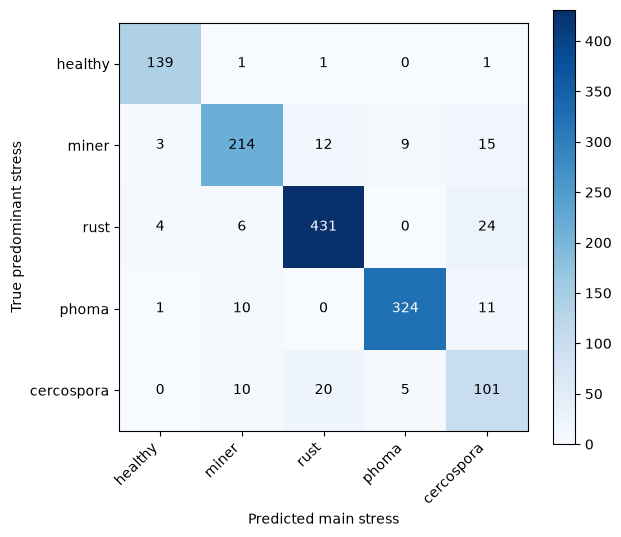


Mean +/- std across folds:
  val_flag_f1                0.844 +/- 0.023
  flag_macro_f1              0.835 +/- 0.022
  exact_match                0.728 +/- 0.029
  f1_miner                   0.802 +/- 0.041
  recall_miner               0.753 +/- 0.073
  f1_rust                    0.922 +/- 0.010
  recall_rust                0.940 +/- 0.008
  f1_phoma                   0.950 +/- 0.027
  recall_phoma               0.952 +/- 0.021
  f1_cercospora              0.664 +/- 0.035
  recall_cercospora          0.683 +/- 0.058
  tuned_flag_macro_f1        0.825 +/- 0.020
  tuned_exact_match          0.715 +/- 0.018
  tuned_f1_miner             0.772 +/- 0.024
  tuned_recall_miner         0.721 +/- 0.092
  tuned_f1_rust              0.926 +/- 0.010
  tuned_recall_rust          0.945 +/- 0.012
  tuned_f1_phoma             0.952 +/- 0.019
  tuned_recall_phoma         0.949 +/- 0.015
  tuned_f1_cercospora        0.651 +/- 0.047
  tuned_recall_cercospora    0.687 +/- 0.149
  ap_miner                 

In [ ]:
# ---- 5-fold CV v2: multi-label flags + predominant head, per-stressor thresholds, main + secondary report ----
# Paste as a new cell AFTER the model cell (and after the earlier CV cell if you like).
# Reuses from earlier cells: df, build_model, set_backbone_trainable, train_tf, eval_tf, set_seed, device,
# NUM_WORKERS, BATCH_SIZE, EPOCHS_HEAD, EPOCHS_FINETUNE, LR_HEAD, LR_FINETUNE, WEIGHT_DECAY, OUT_DIR,
# FLAG_COLS, STRESS_NAMES, DataLoader, tqdm, plus the sklearn / numpy / pandas / torch imports.
import copy
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (precision_recall_fscore_support, roc_auc_score,
                             average_precision_score, accuracy_score)

N_FOLDS = 5
VAL_FRACTION = 0.15
SEED = 42                  # keep identical to the 6-class CV so the folds are the same
LAMBDA_PRED = 0.4          # weight of the predominant-stress head; 0.0 = pure multi-label
THRESH = 0.5               # fixed baseline threshold; per-stressor thresholds are ALSO tuned on each fold's validation slice
THRESH_GRID = np.arange(0.20, 0.81, 0.05)   # candidate thresholds (kept away from the extremes: the val slice is small)
MIN_CKPT_EPOCH = 6         # ignore fine-tune epochs before this when choosing the checkpoint
PATIENCE = None            # train all fine-tune epochs (cosine schedule completes)

# ---- targets ----
FLAG_NAMES = list(FLAG_COLS)                                   # miner, rust, phoma, cercospora
PRED_NAMES = ["healthy", "miner", "rust", "phoma", "cercospora"]   # codes 0..4; code 5 ("multiple") is masked
IGNORE = -100

flags_all = (df[FLAG_COLS].to_numpy() > 0).astype(np.float32)          # (N, 4)
stress_code = df["predominant_stress"].to_numpy().astype(int)          # 0..5
pred_all = np.where(stress_code <= 4, stress_code, IGNORE).astype(np.int64)
labels_all = df["label"].to_numpy()                                     # same labels the 6-class CV used for folds
paths_all = df["path"].astype(str).to_numpy()


# ==== HELPERS START (pure numpy, no torch) ====
def f1_binary(y_true, y_hat):
    tp = int(((y_hat == 1) & (y_true == 1)).sum())
    fp = int(((y_hat == 1) & (y_true == 0)).sum())
    fn = int(((y_hat == 0) & (y_true == 1)).sum())
    d = 2 * tp + fp + fn
    return 2 * tp / d if d else 0.0


def tune_thresholds(y_true, y_prob, grid=THRESH_GRID):
    """Per-stressor threshold maximizing F1 on the validation slice; ties go to the value closest to 0.5."""
    thr = np.full(y_true.shape[1], 0.5)
    for k in range(y_true.shape[1]):
        if y_true[:, k].sum() == 0:
            continue
        best_f, best_t = -1.0, 0.5
        for t in grid:
            f = f1_binary((y_true[:, k] > 0.5).astype(int), (y_prob[:, k] >= t).astype(int))
            if f > best_f + 1e-9 or (abs(f - best_f) <= 1e-9 and abs(t - 0.5) < abs(best_t - 0.5)):
                best_f, best_t = f, float(t)
        thr[k] = best_t
    return thr


def secondary_eval(flags, flag_hat, true_code, main_hat):
    """Main + secondary report, on leaves whose true predominant stress is miner/rust/phoma/cercospora (codes 1-4).
    Secondary stressors = flags other than the main one. Predicted secondary = predicted flags minus the predicted main stress.
    Returns micro and per-stressor secondary precision/recall/F1 and the share of leaves whose whole record
    (main + secondary set) is right."""
    m = (true_code >= 1) & (true_code <= 4)
    ts = (flags[m] > 0.5).astype(int).copy()
    ts[np.arange(len(ts)), true_code[m] - 1] = 0
    ps = flag_hat[m].astype(int).copy()
    mh = main_hat[m]
    has_main = mh >= 1
    ps[np.where(has_main)[0], mh[has_main] - 1] = 0
    ps[~has_main] = 0                                  # head says healthy -> no secondary
    out = {}
    tp, fp, fn = int(((ps == 1) & (ts == 1)).sum()), int(((ps == 1) & (ts == 0)).sum()), int(((ps == 0) & (ts == 1)).sum())
    out["sec_precision"] = tp / (tp + fp) if tp + fp else 0.0
    out["sec_recall"] = tp / (tp + fn) if tp + fn else 0.0
    out["sec_f1"] = 2 * tp / (2 * tp + fp + fn) if 2 * tp + fp + fn else 0.0
    out["record_exact"] = float(((mh == true_code[m]) & (ps == ts).all(1)).mean())
    out["n_leaves"] = int(m.sum())
    out["n_true_secondary"] = int(ts.sum())
    per = {}
    for k, n in enumerate(FLAG_NAMES):
        per[n] = f1_binary(ts[:, k], ps[:, k])
    out["per_stressor_f1"] = per
    return out
# ==== HELPERS END ====


class MultiHeadNet(nn.Module):
    """MobileNetV3 trunk -> head_flags (4 logits, sigmoid) and head_pred (5 logits, softmax)."""
    def __init__(self):
        super().__init__()
        m = build_model(2)                       # reuse the notebook's pretrained model; we drop its last layer
        self.features = m.features               # set_backbone_trainable() freezes/unfreezes this
        self.avgpool = m.avgpool
        self.trunk = m.classifier[:-1]           # Linear(960,1280) + Hardswish + Dropout
        hidden = m.classifier[-1].in_features
        self.head_flags = nn.Linear(hidden, len(FLAG_NAMES))
        self.head_pred = nn.Linear(hidden, len(PRED_NAMES))

    def forward(self, x):
        h = self.avgpool(self.features(x)).flatten(1)
        h = self.trunk(h)
        return self.head_flags(h), self.head_pred(h)


class MLDataset(torch.utils.data.Dataset):
    def __init__(self, idx, transform):
        self.idx, self.transform = idx, transform

    def __len__(self):
        return len(self.idx)

    def __getitem__(self, i):
        j = self.idx[i]
        img = Image.open(paths_all[j]).convert("RGB")
        return self.transform(img), torch.from_numpy(flags_all[j]), int(pred_all[j])


def make_loader_ml(idx, tf, shuffle):
    return DataLoader(MLDataset(idx, tf), batch_size=BATCH_SIZE, shuffle=shuffle,
                      num_workers=NUM_WORKERS, pin_memory=(device.type == "cuda"))


def macro_f1_flags(y_true, y_prob, thr=THRESH):
    y_hat = (y_prob >= thr).astype(int)
    _, _, f1, _ = precision_recall_fscore_support(y_true, y_hat, average=None, zero_division=0)
    return float(np.mean(f1))


def run_epoch_ml(model, loader, bce, ce, optimizer=None, desc=""):
    train = optimizer is not None
    model.train(train)
    total, n = 0.0, 0
    probs, ys = [], []
    with torch.set_grad_enabled(train):
        for x, yf, yp in tqdm(loader, desc=desc, leave=False):
            x, yf, yp = x.to(device), yf.to(device), yp.to(device)
            lf, lp = model(x)
            loss = bce(lf, yf)
            if LAMBDA_PRED > 0 and (yp != IGNORE).any():
                loss = loss + LAMBDA_PRED * ce(lp, yp)
            if train:
                optimizer.zero_grad(set_to_none=True)
                loss.backward()
                optimizer.step()
            total += loss.item() * x.size(0)
            n += x.size(0)
            probs.append(torch.sigmoid(lf).detach().cpu())
            ys.append(yf.cpu())
    P, Y = torch.cat(probs).numpy(), torch.cat(ys).numpy()
    return total / n, macro_f1_flags(Y, P), float(((P >= THRESH) == (Y > 0.5)).all(1).mean())


def train_fold_ml(train_idx, val_idx, fold):
    set_seed(SEED + fold)
    model = MultiHeadNet().to(device)
    # soft pos_weight (sqrt of neg/pos, capped) so rare stressors count more without over-predicting them
    pos = flags_all[train_idx].sum(0)
    neg = len(train_idx) - pos
    pw = np.clip(np.sqrt(neg / np.maximum(pos, 1)), 1.0, 4.0)
    bce = nn.BCEWithLogitsLoss(pos_weight=torch.tensor(pw, dtype=torch.float32).to(device))
    pc = np.bincount(pred_all[train_idx][pred_all[train_idx] != IGNORE], minlength=len(PRED_NAMES))
    cw = pc.sum() / (len(PRED_NAMES) * np.maximum(pc, 1))
    ce = nn.CrossEntropyLoss(weight=torch.tensor(cw, dtype=torch.float32).to(device), ignore_index=IGNORE)
    train_loader = make_loader_ml(train_idx, train_tf, True)
    val_loader = make_loader_ml(val_idx, eval_tf, False)
    best = {"f1": -1.0, "state": None, "epoch": None}

    def phase(epochs, lr, trainable, label, patience=None):
        set_backbone_trainable(model, trainable)
        params = [p for p in model.parameters() if p.requires_grad]
        opt = torch.optim.AdamW(params, lr=lr, weight_decay=WEIGHT_DECAY)
        sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=max(epochs, 1))
        bad = 0
        for ep in range(epochs):
            tr_loss, tr_f1, tr_em = run_epoch_ml(model, train_loader, bce, ce, opt, f"f{fold} {label} {ep+1} train")
            va_loss, va_f1, va_em = run_epoch_ml(model, val_loader, bce, ce, None, f"f{fold} {label} {ep+1} val")
            sched.step()
            eligible = (label == "ft" and ep + 1 >= MIN_CKPT_EPOCH)
            improved = eligible and va_f1 > best["f1"]
            if improved:
                best.update(f1=va_f1, state=copy.deepcopy(model.state_dict()), epoch=f"{label}{ep+1}")
                bad = 0
            elif eligible:
                bad += 1
            tqdm.write(f"  [fold {fold}] {label} {ep+1}/{epochs} train loss {tr_loss:.3f} F1 {tr_f1:.3f} | "
                       f"val loss {va_loss:.3f} F1 {va_f1:.3f} exact {va_em:.3f}{'  <- best' if improved else ''}")
            if patience is not None and bad >= patience:
                tqdm.write(f"  [fold {fold}] early stop")
                break

    phase(EPOCHS_HEAD, LR_HEAD, False, "head")
    phase(EPOCHS_FINETUNE, LR_FINETUNE, True, "ft", patience=PATIENCE)
    model.load_state_dict(best["state"])
    pv, _ = predict_ml(model, val_idx)
    thr = tune_thresholds(flags_all[val_idx], pv)     # validation slice only: the test fold is never used
    return model, best, thr


@torch.no_grad()
def predict_ml(model, idx):
    model.eval()
    loader = make_loader_ml(idx, eval_tf, False)
    pf, pp = [], []
    for x, _, _ in loader:
        lf, lp = model(x.to(device))
        pf.append(torch.sigmoid(lf).cpu())
        pp.append(torch.softmax(lp, 1).cpu())
    return torch.cat(pf).numpy(), torch.cat(pp).numpy()


def fold_metrics(y_true, y_prob, pred_prob, true_code, thr):
    row = {}
    for tag, t in (("", np.full(len(FLAG_NAMES), THRESH)), ("tuned_", thr)):
        y_hat = (y_prob >= t).astype(int)
        p, r, f1, _ = precision_recall_fscore_support(y_true, y_hat, average=None, zero_division=0)
        row[f"{tag}flag_macro_f1"] = float(f1.mean())
        row[f"{tag}exact_match"] = float((y_hat == (y_true > 0.5)).all(1).mean())
        for k, n in enumerate(FLAG_NAMES):
            row[f"{tag}f1_{n}"], row[f"{tag}recall_{n}"] = float(f1[k]), float(r[k])
    for k, n in enumerate(FLAG_NAMES):
        try:
            row[f"ap_{n}"] = float(average_precision_score(y_true[:, k], y_prob[:, k]))
        except ValueError:
            row[f"ap_{n}"] = float("nan")
        row[f"thr_{n}"] = float(thr[k])
    mask = true_code != 5
    row["main_acc"] = float((pred_prob.argmax(1)[mask] == true_code[mask]).mean())
    sec = secondary_eval(y_true, (y_prob >= thr).astype(int), true_code, pred_prob.argmax(1))
    row["sec_f1"], row["record_exact"] = sec["sec_f1"], sec["record_exact"]
    return row


skf = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED)
oof_flag_prob = np.full((len(df), len(FLAG_NAMES)), np.nan, dtype=np.float32)
oof_pred_prob = np.full((len(df), len(PRED_NAMES)), np.nan, dtype=np.float32)
oof_thr = np.full((len(df), len(FLAG_NAMES)), np.nan, dtype=np.float32)
fold_rows = []

for fold, (trainval_idx, test_idx) in enumerate(skf.split(np.zeros(len(df)), labels_all), start=1):
    tr_idx, va_idx = train_test_split(trainval_idx, test_size=VAL_FRACTION,
                                      stratify=labels_all[trainval_idx], random_state=SEED + fold)
    print(f"\n=== Fold {fold}/{N_FOLDS}: train {len(tr_idx)}, val {len(va_idx)}, test {len(test_idx)} ===")
    model, best, thr = train_fold_ml(tr_idx, va_idx, fold)
    pf, pp = predict_ml(model, test_idx)
    oof_flag_prob[test_idx], oof_pred_prob[test_idx], oof_thr[test_idx] = pf, pp, thr
    row = {"fold": fold, "best_epoch": best["epoch"], "val_flag_f1": best["f1"]}
    row.update(fold_metrics(flags_all[test_idx], pf, pp, stress_code[test_idx], thr))
    fold_rows.append(row)
    print(f"Fold {fold} test: flag macro-F1 {row['flag_macro_f1']:.3f} (tuned {row['tuned_flag_macro_f1']:.3f}), "
          f"main acc {row['main_acc']:.3f}, secondary F1 {row['sec_f1']:.3f} (best at {best['epoch']}); "
          f"thresholds {np.round(thr, 2).tolist()}")
    del model

res = pd.DataFrame(fold_rows)
print("\nPer-fold results:")
print(res.round(3).to_string(index=False))

assert not np.isnan(oof_flag_prob).any()
y_fixed = (oof_flag_prob >= THRESH).astype(int)
y_tuned = (oof_flag_prob >= oof_thr).astype(int)          # each image uses the thresholds picked in ITS fold's validation slice
print("\nPooled out-of-fold, per stressor (fixed 0.5 vs thresholds tuned on validation):")
rows = []
for k, n in enumerate(FLAG_NAMES):
    for tag, yh in (("0.5", y_fixed), ("tuned", y_tuned)):
        p, r, f1, _ = precision_recall_fscore_support(flags_all[:, k], yh[:, k], average="binary", zero_division=0)
        rows.append({"stressor": n, "threshold": tag, "precision": p, "recall": r, "f1": f1})
pool = pd.DataFrame(rows)
print(pool.round(3).to_string(index=False))
thr_df = pd.DataFrame({"mean_thr": oof_thr.mean(0), "min_thr": oof_thr.min(0), "max_thr": oof_thr.max(0)}, index=FLAG_NAMES)
print("\nTuned thresholds across folds:")
print(thr_df.round(2).to_string())
auc = pd.DataFrame({"roc_auc": [roc_auc_score(flags_all[:, k], oof_flag_prob[:, k]) for k in range(len(FLAG_NAMES))],
                    "avg_precision": [average_precision_score(flags_all[:, k], oof_flag_prob[:, k]) for k in range(len(FLAG_NAMES))]},
                   index=FLAG_NAMES)
print("\nThreshold-free metrics:")
print(auc.round(3).to_string())
for tag, yh in (("0.5", y_fixed), ("tuned", y_tuned)):
    print(f"  exact match, all 4 flags right ({tag}): {(yh == (flags_all > 0.5)).all(1).mean():.3f}")

# ---- main stress (predominant head) + secondary flags ----
main_hat = oof_pred_prob.argmax(1)
mk = pred_all != IGNORE
print("\nMain stress (predominant head; 'multiple' leaves excluded):")
print(classification_report(pred_all[mk], main_hat[mk], labels=list(range(len(PRED_NAMES))),
                            target_names=PRED_NAMES, digits=3, zero_division=0))
sec = secondary_eval(flags_all, y_tuned, stress_code, main_hat)
print(f"Secondary stressors (leaves with a single predominant stress: {sec['n_leaves']}; "
      f"true secondary flags: {sec['n_true_secondary']}):")
print(f"  precision {sec['sec_precision']:.3f}  recall {sec['sec_recall']:.3f}  F1 {sec['sec_f1']:.3f}")
print("  per-stressor secondary F1:", {k: round(v, 3) for k, v in sec["per_stressor_f1"].items()})
print(f"  whole record right (main + secondary set): {sec['record_exact']:.3f}")

cm = confusion_matrix(pred_all[mk], main_hat[mk], labels=list(range(len(PRED_NAMES))))
fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(len(PRED_NAMES))); ax.set_xticklabels(PRED_NAMES, rotation=45, ha="right")
ax.set_yticks(range(len(PRED_NAMES))); ax.set_yticklabels(PRED_NAMES)
ax.set_xlabel("Predicted main stress"); ax.set_ylabel("True predominant stress")
for i in range(len(PRED_NAMES)):
    for j in range(len(PRED_NAMES)):
        ax.text(j, i, cm[i, j], ha="center", va="center", color="white" if cm[i, j] > cm.max() / 2 else "black")
fig.colorbar(im); fig.tight_layout()
OUT_DIR.mkdir(exist_ok=True)
fig.savefig(OUT_DIR / "cv_ml2_main_confusion_matrix.png", dpi=150)
plt.show()

num_cols = [c for c in res.columns if c not in ("fold", "best_epoch")]
print("\nMean +/- std across folds:")
for c in num_cols:
    print(f"  {c:<26} {res[c].mean():.3f} +/- {res[c].std():.3f}")
res.to_csv(OUT_DIR / "cv_ml2_fold_results.csv", index=False)
oof = pd.DataFrame(oof_flag_prob, columns=[f"p_{n}" for n in FLAG_NAMES])
for k, n in enumerate(FLAG_NAMES):
    oof[f"thr_{n}"] = oof_thr[:, k]
for k, n in enumerate(PRED_NAMES):
    oof[f"main_{n}"] = oof_pred_prob[:, k]
oof.insert(0, "id", df["id"].to_numpy())
oof.to_csv(OUT_DIR / "cv_ml2_oof_predictions.csv", index=False)
print("\nSaved: outputs/cv_ml2_fold_results.csv, cv_ml2_oof_predictions.csv, cv_ml2_main_confusion_matrix.png")

In [ ]:
def run_epoch(model, loader, criterion, optimizer=None, desc=""):
    train = optimizer is not None
    model.train(train)
    total_loss = 0.0
    all_preds, all_labels = [], []
    with torch.set_grad_enabled(train):
        for x, y in tqdm(loader, desc=desc, leave=False):
            x, y = x.to(device), y.to(device)
            logits = model(x)
            loss = criterion(logits, y)
            if train:
                optimizer.zero_grad(set_to_none=True)
                loss.backward()
                optimizer.step()
            total_loss += loss.item() * x.size(0)
            all_preds.append(logits.argmax(1).cpu())
            all_labels.append(y.cpu())
    preds = torch.cat(all_preds).numpy()
    labels = torch.cat(all_labels).numpy()
    n = len(labels)
    return total_loss / n, float((preds == labels).mean()), f1_score(labels, preds, average="macro")


criterion = nn.CrossEntropyLoss(weight=class_weights)
history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": [], "val_f1": []}
best = {"f1": -1.0, "state": None}


def train_phase(epochs, lr, backbone_trainable, label):
    set_backbone_trainable(model, backbone_trainable)
    params = [p for p in model.parameters() if p.requires_grad]
    optimizer = torch.optim.AdamW(params, lr=lr, weight_decay=WEIGHT_DECAY)
    scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=max(epochs, 1))
    for epoch in range(epochs):
        t0 = time.time()
        tag = f"[{label}] {epoch + 1}/{epochs}"
        tr_loss, tr_acc, _ = run_epoch(model, train_loader, criterion, optimizer, desc=f"{tag} train")
        va_loss, va_acc, va_f1 = run_epoch(model, val_loader, criterion, desc=f"{tag} val")
        scheduler.step()
        history["train_loss"].append(tr_loss)
        history["val_loss"].append(va_loss)
        history["train_acc"].append(tr_acc)
        history["val_acc"].append(va_acc)
        history["val_f1"].append(va_f1)
        marker = ""
        if va_f1 > best["f1"]:
            best["f1"] = va_f1
            best["state"] = copy.deepcopy(model.state_dict())
            torch.save(best["state"], OUT_DIR / "best_model.pt")
            marker = "  <- best"
        tqdm.write(f"[{label}] epoch {epoch + 1}/{epochs}  "
                   f"train loss {tr_loss:.3f} acc {tr_acc:.3f} | "
                   f"val loss {va_loss:.3f} acc {va_acc:.3f} macro-F1 {va_f1:.3f}  "
                   f"({time.time() - t0:.0f}s){marker}")


train_phase(EPOCHS_HEAD, LR_HEAD, backbone_trainable=False, label="head")
train_phase(EPOCHS_FINETUNE, LR_FINETUNE, backbone_trainable=True, label="finetune")
print("Best validation macro-F1:", round(best["f1"], 4))

NameError: name 'model' is not defined

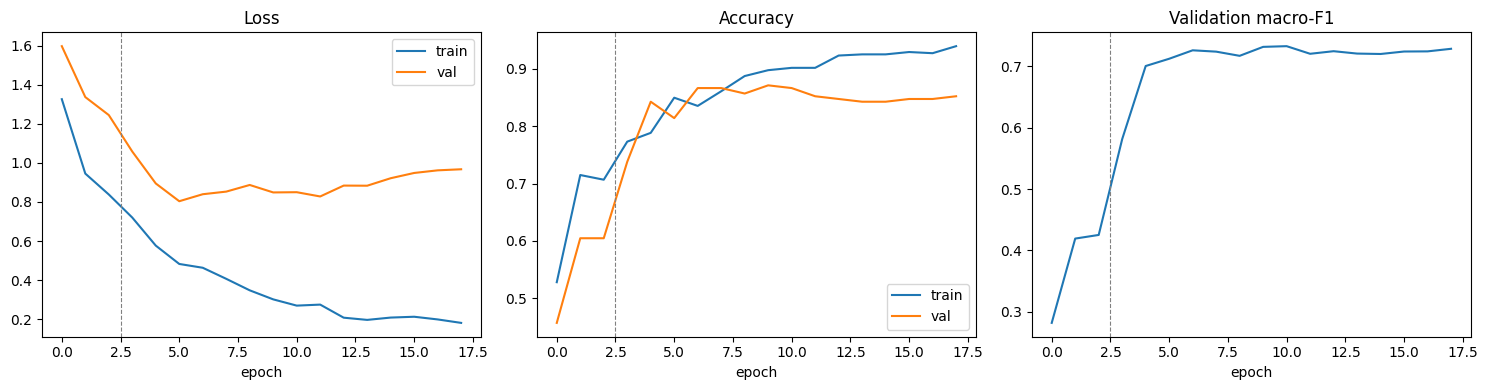

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].plot(history["train_loss"], label="train")
axes[0].plot(history["val_loss"], label="val")
axes[0].set_title("Loss")
axes[0].legend()
axes[1].plot(history["train_acc"], label="train")
axes[1].plot(history["val_acc"], label="val")
axes[1].set_title("Accuracy")
axes[1].legend()
axes[2].plot(history["val_f1"])
axes[2].set_title("Validation macro-F1")
for ax in axes:
    ax.set_xlabel("epoch")
    ax.axvline(EPOCHS_HEAD - 0.5, color="gray", linestyle="--", linewidth=0.8)
plt.tight_layout()
plt.savefig(OUT_DIR / "training_curves.png", dpi=120)
plt.show()

## 6. Test-set evaluation

Look at **per-class recall** and the confusion matrix, not only overall accuracy. Look at which classes get confused with each other, and at the smaller classes, where a good overall accuracy can hide poor recall.

              precision    recall  f1-score   support

     healthy      1.000     0.955     0.977        22
       miner      0.878     0.947     0.911        38
        rust      0.843     0.855     0.849        69
       phoma      1.000     0.981     0.990        52
  cercospora      0.571     0.600     0.585        20
    multiple      0.000     0.000     0.000         9

    accuracy                          0.852       210
   macro avg      0.715     0.723     0.719       210
weighted avg      0.843     0.852     0.847       210



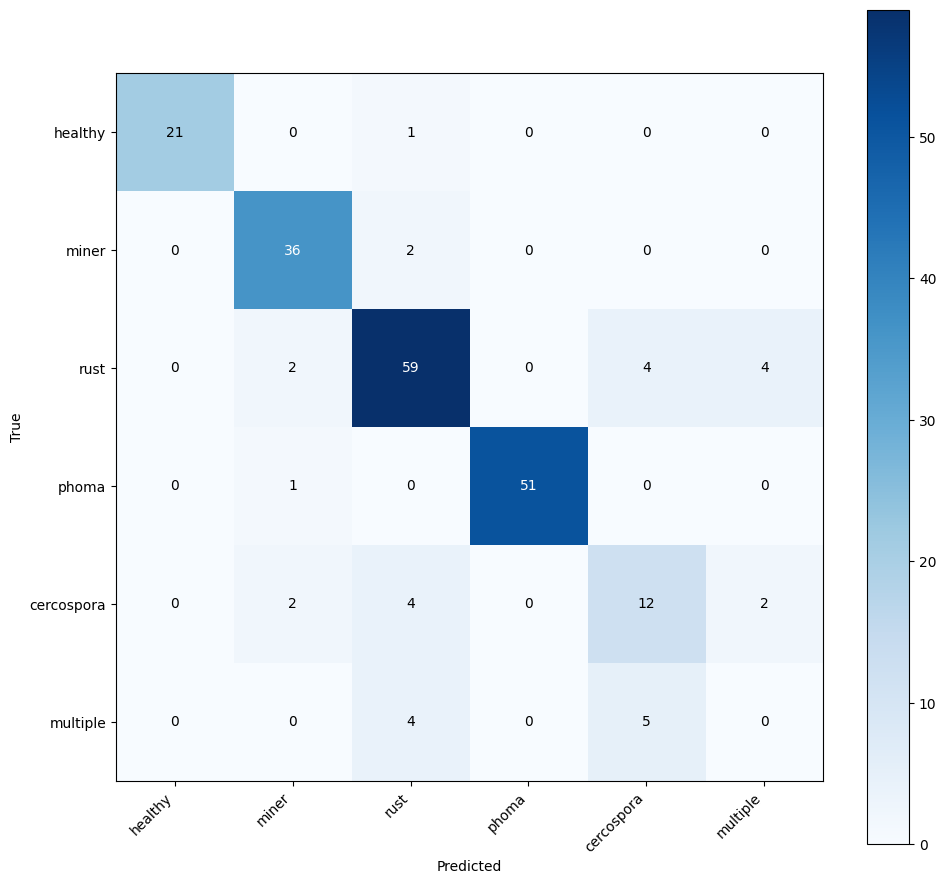

In [ ]:
model.load_state_dict(best["state"])
model.eval()


@torch.no_grad()
def predict_loader(model, loader):
    model.eval()
    labels, preds = [], []
    for x, y in loader:
        logits = model(x.to(device))
        preds.append(logits.argmax(1).cpu())
        labels.append(y)
    return torch.cat(labels).numpy(), torch.cat(preds).numpy()


y_true, y_pred = predict_loader(model, test_loader)
print(classification_report(y_true, y_pred, labels=list(range(num_classes)),
                            target_names=class_names, digits=3, zero_division=0))

cm = confusion_matrix(y_true, y_pred, labels=list(range(num_classes)))
fig, ax = plt.subplots(figsize=(1.2 * num_classes + 3, 1.2 * num_classes + 2))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(num_classes))
ax.set_xticklabels(class_names, rotation=45, ha="right")
ax.set_yticks(range(num_classes))
ax.set_yticklabels(class_names)
ax.set_xlabel("Predicted")
ax.set_ylabel("True")
for i in range(num_classes):
    for j in range(num_classes):
        ax.text(j, i, cm[i, j], ha="center", va="center",
                color="white" if cm[i, j] > cm.max() / 2 else "black")
plt.colorbar(im)
plt.tight_layout()
plt.savefig(OUT_DIR / "confusion_matrix.png", dpi=120)
plt.show()

## 7. Grad-CAM: is the model looking at lesions?

High accuracy means little if the model is keying on the background, the leaf edge, or a hand holding the leaf. These overlays show which regions pushed the prediction. Check that the hot areas sit on lesions, in both correct and incorrect predictions.

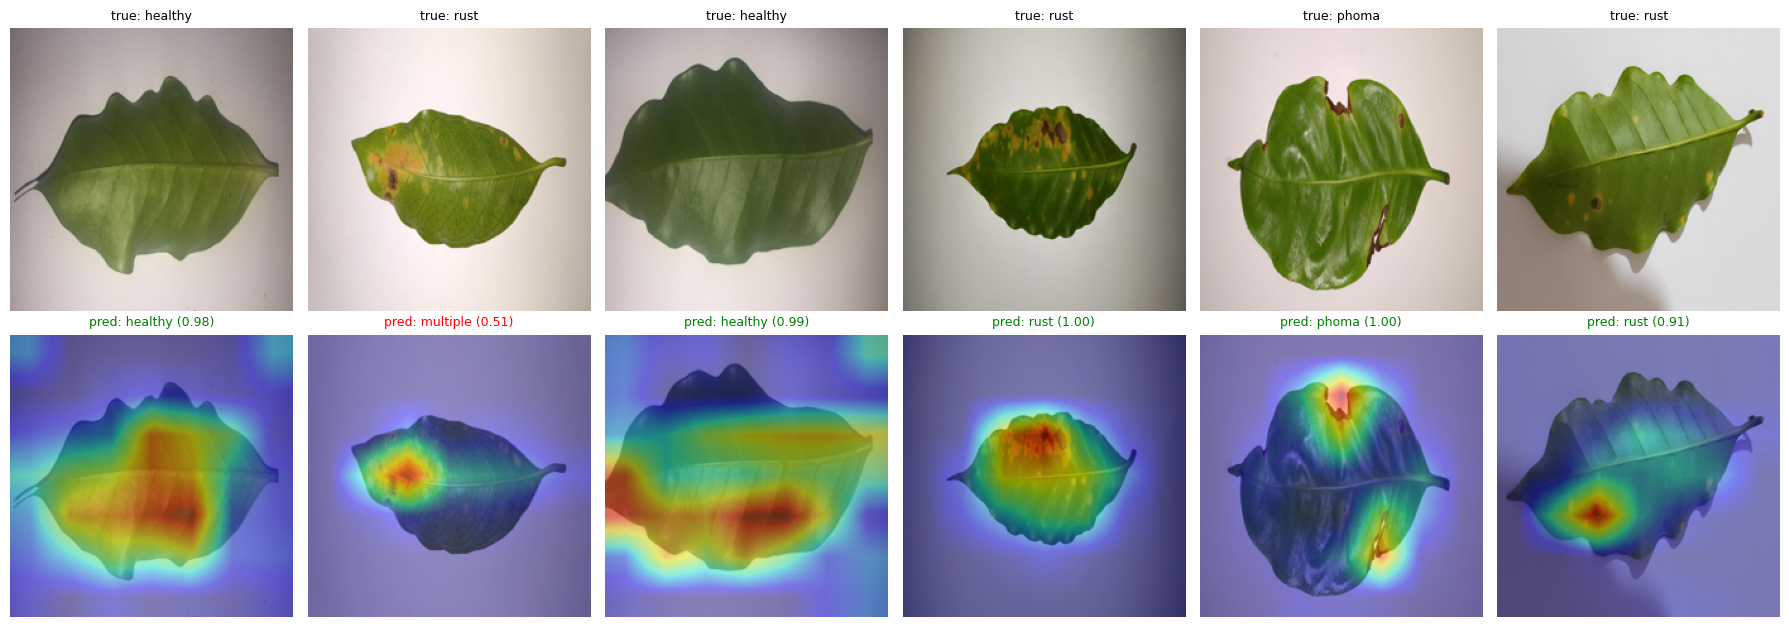

In [ ]:
def grad_cam(model, img_tensor, target_class=None):
    model.eval()
    layer = model.features[-1]
    store = {}

    def fwd_hook(module, inputs, output):
        store["act"] = output
        output.register_hook(lambda g: store.__setitem__("grad", g))

    handle = layer.register_forward_hook(fwd_hook)
    x = img_tensor.unsqueeze(0).to(device).requires_grad_(True)
    logits = model(x)
    probs = F.softmax(logits, dim=1)[0].detach().cpu()
    cls = int(logits.argmax(1)) if target_class is None else int(target_class)
    model.zero_grad()
    logits[0, cls].backward()
    handle.remove()

    act = store["act"][0]
    grad = store["grad"][0]
    w = grad.mean(dim=(1, 2), keepdim=True)
    cam = F.relu((w * act).sum(0))
    cam = cam / (cam.max() + 1e-8)
    cam = F.interpolate(cam[None, None], size=(IMG_SIZE, IMG_SIZE),
                        mode="bilinear", align_corners=False)[0, 0]
    return cam.detach().cpu().numpy(), cls, probs


def show_gradcams(n=6, seed=0):
    rng = random.Random(seed)
    idxs = rng.sample(range(len(test_ds)), min(n, len(test_ds)))
    fig, axes = plt.subplots(2, len(idxs), figsize=(3 * len(idxs), 6.4), squeeze=False)
    for col, i in enumerate(idxs):
        path, true_y = test_ds.samples[i]
        pil = Image.open(path).convert("RGB")
        x = eval_tf(pil)
        cam, pred, probs = grad_cam(model, x)
        shown = np.asarray(pil.resize((IMG_SIZE, IMG_SIZE)))
        axes[0, col].imshow(shown)
        axes[0, col].set_title(f"true: {class_names[true_y]}", fontsize=9)
        axes[0, col].axis("off")
        axes[1, col].imshow(shown)
        axes[1, col].imshow(cam, cmap="jet", alpha=0.45)
        axes[1, col].set_title(f"pred: {class_names[pred]} ({probs[pred]:.2f})", fontsize=9,
                               color="green" if pred == true_y else "red")
        axes[1, col].axis("off")
    plt.tight_layout()
    plt.savefig(OUT_DIR / "gradcam_examples.png", dpi=120)
    plt.show()


show_gradcams(n=6, seed=0)

## 8. Low-resolution robustness check

Each test image is shrunk to `res x res` and then scaled back up to the model's input size. This shows how quickly performance falls as image detail disappears, and which classes lose recall first.

Important limitation: the model was trained at full resolution, so this measures its **robustness to degraded inputs**. It is not the same as training and testing at each resolution. The proper ablation for your project is to retrain at each resolution (change `IMG_SIZE` and the transforms, rerun) and compare the curves.

res   macro-F1     healthy       miner        rust       phoma  cercospora    multiple
224   0.719          0.955       0.947       0.855       0.981       0.600       0.000
160   0.725          0.955       0.868       0.870       0.981       0.750       0.000
112   0.770          1.000       0.868       0.913       1.000       0.750       0.111
64    0.719          1.000       0.842       0.783       0.981       0.750       0.111
32    0.542          1.000       0.684       0.478       0.673       0.500       0.111


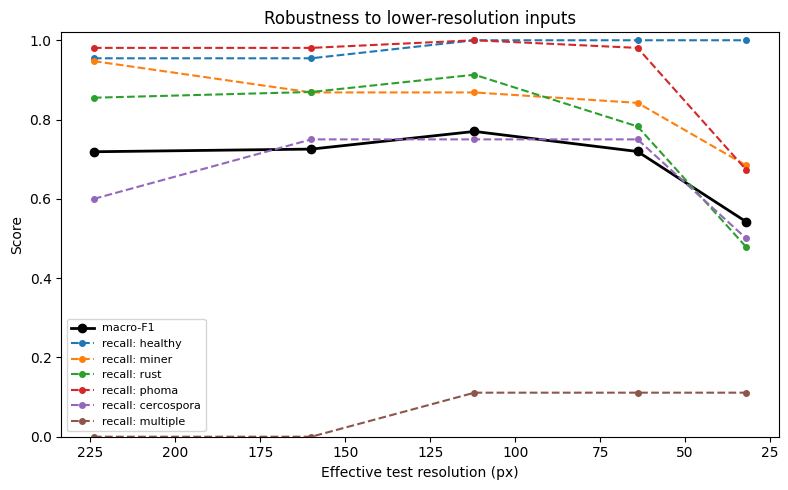

In [ ]:
def make_eval_tf_at_res(res):
    return transforms.Compose([
        transforms.Resize((res, res)),
        transforms.Resize((IMG_SIZE, IMG_SIZE)),
        transforms.ToTensor(),
        transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
    ])


RESOLUTIONS = [224, 160, 112, 64, 32]
ablation = []
for res in RESOLUTIONS:
    ds = LeafDataset(samples_for("test"), transform=make_eval_tf_at_res(res))
    dl = DataLoader(ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS)
    yt, yp = predict_loader(model, dl)
    macro = f1_score(yt, yp, average="macro")
    rec = recall_score(yt, yp, labels=list(range(num_classes)), average=None, zero_division=0)
    ablation.append((res, macro, rec))

header = "res   macro-F1  " + "  ".join(f"{c[:10]:>10}" for c in class_names)
print(header)
for res, macro, rec in ablation:
    print(f"{res:<5} {macro:<9.3f} " + "  ".join(f"{r:>10.3f}" for r in rec))

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(RESOLUTIONS, [a[1] for a in ablation], "k-o", linewidth=2, label="macro-F1")
for k, name in enumerate(class_names):
    ax.plot(RESOLUTIONS, [a[2][k] for a in ablation], "--o", markersize=4, label=f"recall: {name}")
ax.set_xlabel("Effective test resolution (px)")
ax.set_ylabel("Score")
ax.set_ylim(0, 1.02)
ax.invert_xaxis()
ax.legend(fontsize=8)
ax.set_title("Robustness to lower-resolution inputs")
plt.tight_layout()
plt.savefig(OUT_DIR / "resolution_robustness.png", dpi=120)
plt.show()

## 9. Predict on a single image

In [1]:
@torch.no_grad()
def predict_image(path, topk=3):
    model.eval()
    img = Image.open(path).convert("RGB")
    x = eval_tf(img).unsqueeze(0).to(device)
    probs = F.softmax(model(x), dim=1)[0].cpu()
    top = torch.topk(probs, k=min(topk, num_classes))
    for p, idx in zip(top.values, top.indices):
        print(f"{class_names[int(idx)]:<24} {float(p):.3f}")
    return class_names[int(top.indices[0])]


# Example:
predict_image("leaf_images/1.jpg")

NameError: name 'torch' is not defined